# Análise exploratória — Roubo de rua no Município do Rio de Janeiro (2003–2023)

**Autor:** Raphael Cortes · **Curso:** Sistemas de Informação (6º período) — UNILASALLE-RJ
**Disciplina:** Linguagem de Programação (Análise e Visualização de Dados com Python) · **Semestre:** 2026.2
**Professor orientador:** Prof. Alexandre Neves Louzada

**Fonte:** [DATA.RIO — Tabela 2488](https://www.data.rio/documents/5e15538d3a1b47e7a356463a324b21b7/about) (IPP, a partir de dados do ISP-RJ)

Este notebook documenta a exploração preliminar, a prototipação e a validação das métricas.
A lógica definitiva foi consolidada nos módulos reutilizáveis de `src/` (`etl.py`, `analysis.py`);
aqui eles são importados e inspecionados passo a passo.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import plotly.io as pio
from scipy import stats

from src import etl, analysis

# Interativo no Jupyter + PNG embutido (para visualização no GitHub), se o kaleido estiver disponível
try:
    import plotly.graph_objects as go
    pio.to_image(go.Figure(), format="png")
    pio.renderers.default = "notebook_connected+png"
except Exception:
    pio.renderers.default = "notebook_connected"
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

INFO | Chromium init'ed with kwargs {}


INFO | Found chromium path: /usr/bin/google-chrome


INFO | Temp directory created: /tmp/tmpb_agntat.


INFO | Opening browser.


INFO | Temp directory created: /tmp/tmphlfizuha.


INFO | Temporary directory at: /tmp/tmphlfizuha


... (17 outputs left out)

INFO | Cancelling tasks.


INFO | Exiting Kaleido/Choreo.


INFO | TemporaryDirectory.cleanup() worked.


INFO | shutil.rmtree worked.


## 1. Inspeção do arquivo bruto

A planilha é um `.xls` (Excel 97–2003) desenhado para impressão: título, cabeçalho em duas linhas,
meses em colunas, notas de rodapé e marcadores textuais de ausência (`..` e `...`).

In [2]:
raw = etl.read_raw()
print("Dimensões da planilha bruta:", raw.shape)
raw.head(12)

Dimensões da planilha bruta: (40, 18)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,DATA.RIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"Tabela 2488 - Incidências de roubo de rua, por...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Ano,Incidências de Roubo de Rua¹,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez,Total2,Diferença Absoluta2,Diferença %2,População3,Taxa por 100 mil hab2
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Rodapé com fonte e notas metodológicas
raw.iloc[31:, 0].dropna().tolist()

['Fonte: Instituto de Segurança Pública.  Disponível em <http://www.ispdados.rj.gov.br/> acesso em 27/11/2023',
 'Notas:',
 '1 - Engloba roubo a transeunte, roubo de celular e roubo em coletivo.',
 '2 - Cálculos e tabulação: IPP, Coordenadoria Técnica de Informações da Cidade.',
 '3 - Projeção realizada pelo ISP, referente a Dezembro ou do último mês disponível no ano. No ano de 2022, a última projeção da população divulgada pelo ISP refere-se ao mês de Julho.',
 '... Dado numérico não disponível',
 '.. Não se aplica dado numérico']

## 2. ETL

`etl.run()` localiza o cabeçalho dinamicamente, converte marcadores de ausência em `NaN`
(registrando cada célula), reorganiza para formato longo, cria métricas derivadas,
valida os totais publicados e persiste em Parquet e CSV.gz.

In [4]:
mensal, anual, report = etl.run()
print({k: v for k, v in report.items() if k != "valores_ausentes_convertidos"})

INFO | Lendo tabela_2488_roubo_de_rua.xls


INFO | 21 anos encontrados; 8 células ausentes convertidas em NaN


INFO | Gravado roubo_rua_mensal (250 linhas) em Parquet e CSV.gz


INFO | Gravado roubo_rua_anual (21 linhas) em Parquet e CSV.gz


INFO | Validação: totais OK=True | erro máx. taxa=0.0000


{'fonte': 'https://www.data.rio/documents/5e15538d3a1b47e7a356463a324b21b7/about', 'sha256_bruto': '4df1da3485f3d4d3cd239ffba17672b788881f5e158033e9b48fec8eb04c3a50', 'total_confere': True, 'anos_total_divergente': [], 'dif_abs_confere': True, 'dif_pct_max_erro_pp': 0.0, 'taxa_max_erro': 0.0, 'periodo_coberto': ['2003-01', '2023-10'], 'n_meses': 250, 'meses_faltantes_na_serie': 0, 'duplicatas': 0, 'ocorrencias_negativas': 0}


In [5]:
pd.DataFrame(report["valores_ausentes_convertidos"])

,celula,valor_original
0,2003/dif_abs_oficial,..
1,2003/dif_pct_oficial,..
2,2023/Nov,..
3,2023/Dez,..
4,2023/dif_abs_oficial,..
5,2023/dif_pct_oficial,..
6,2023/populacao,..
7,2023/taxa_100k_oficial,..


In [6]:
mensal.info()
mensal.head()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   data                  250 non-null    datetime64[us]
 1   periodo               250 non-null    str           
 2   ano                   250 non-null    int64         
 3   mes                   250 non-null    int64         
 4   mes_abrev             250 non-null    str           
 5   ocorrencias           250 non-null    Int64         
 6   dias_no_mes           250 non-null    int64         
 7   media_diaria          250 non-null    float64       
 8   populacao_ref         250 non-null    float64       
 9   populacao_imputada    250 non-null    bool          
 10  taxa_anualizada_100k  250 non-null    float64       
 11  flag_greve_pc_2017    250 non-null    bool          
 12  flag_pandemia         250 non-null    bool          
dtypes: Int64(1), bool(3), datetime6

,data,periodo,ano,mes,mes_abrev,ocorrencias,dias_no_mes,media_diaria,populacao_ref,populacao_imputada,taxa_anualizada_100k,flag_greve_pc_2017,flag_pandemia
0,2003-01-01,2003-01,2003,1,Jan,1938,31,62.516129,6.012069e+06,False,379.543032,False,False
1,2003-02-01,2003-02,2003,2,Fev,2074,28,74.071429,6.012069e+06,False,449.696662,False,False
2,2003-03-01,2003-03,2003,3,Mar,1959,31,63.193548,6.012069e+06,False,383.655727,False,False
3,2003-04-01,2003-04,2003,4,Abr,2027,30,67.566667,6.012069e+06,False,410.205461,False,False
4,2003-05-01,2003-05,2003,5,Mai,2131,31,68.741935,6.012069e+06,False,417.340661,False,False


### 2.1 Conferência dos valores oficiais

Os totais, as diferenças e as taxas recalculados batem exatamente com os publicados.

In [7]:
anual[["ano", "total_oficial", "total_calculado", "dif_pct_oficial", "dif_pct_calculada",
       "taxa_100k_oficial", "taxa_100k_calculada"]].round(2)

,ano,total_oficial,total_calculado,dif_pct_oficial,dif_pct_calculada,taxa_100k_oficial,taxa_100k_calculada
0,2003,23701.0,23701,NaN,NaN,394.22,394.22
1,2004,25999.0,25999,9.70,9.70,429.17,429.17
2,2005,34358.0,34358,32.15,32.15,562.86,562.86
3,2006,41772.0,41772,21.58,21.58,679.14,679.14
4,2007,49055.0,49055,17.44,17.44,791.51,791.51
5,2008,53615.0,53615,9.30,9.30,858.54,858.54
6,2009,53486.0,53486,-0.24,-0.24,850.20,850.20
7,2010,46176.0,46176,-13.67,-13.67,728.73,728.73
8,2011,37576.0,37576,-18.62,-18.62,589.87,589.87
9,2012,31496.0,31496,-16.18,-16.18,491.60,491.60


## 3. Estatística descritiva

In [8]:
mensal[["ocorrencias", "media_diaria", "taxa_anualizada_100k"]].describe().round(2)

,ocorrencias,media_diaria,taxa_anualizada_100k
count,250.0,250.00,250.00
mean,3750.73,123.28,697.48
std,1174.02,38.61,209.67
min,1843.0,59.45,351.27
25%,2891.25,94.07,534.28
50%,3619.0,118.63,682.73
75%,4418.25,145.56,848.92
max,6981.0,225.19,1246.91


In [9]:
# Dispersão intra-anual: coeficiente de variação (%) da média diária
cv = mensal.groupby("ano")["media_diaria"].agg(lambda x: x.std(ddof=1) / x.mean() * 100).round(1)
cv.to_frame("CV (%)").T

ano,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
CV (%),6.3,6.4,8.1,7.0,6.4,3.4,10.3,9.9,9.3,10.3,10.3,4.0,9.9,7.7,24.4,5.0,13.5,31.4,12.4,4.4,6.5


In [10]:
# A população explica a variação da taxa? (correlação fraca)
comp = anual[anual["ano_completo"]]
r, p = stats.pearsonr(comp["populacao"], comp["taxa_100k_oficial"])
print(f"Pearson r = {r:.3f} (p = {p:.3f}); crescimento populacional 2003→2022: "
      f"{(comp['populacao'].iloc[-1] / comp['populacao'].iloc[0] - 1) * 100:.1f}%")

Pearson r = 0.353 (p = 0.127); crescimento populacional 2003→2022: 12.7%


## 4. RQ1 — Tendência

In [11]:
met = analysis.compute_metrics(mensal, anual)
figs = analysis.build_figures(mensal, anual, met)
{k: (round(v, 2) if isinstance(v, float) else v) for k, v in met["rq1"].items()}

{'taxa_2003': np.float64(394.22),
 'taxa_2008': np.float64(858.54),
 'taxa_2012': np.float64(491.6),
 'taxa_2017': np.float64(1030.31),
 'taxa_2018': np.float64(1023.47),
 'taxa_2022': np.float64(561.42),
 'taxa_2023_anualizada_jan_out': np.float64(460.0),
 'ano_pico': 2017,
 'taxa_pico': np.float64(1030.31),
 'total_2003_2022': 911734,
 'total_serie_ate_out_2023': 937682,
 'var_fases_pct': {'2003–2008': np.float64(117.779452921955),
  '2008–2012': np.float64(-42.739755295978256),
  '2012–2017': np.float64(109.58162523433694),
  '2017–2022': np.float64(-45.50964434822789)},
 'var_2003_2022_pct': np.float64(42.41),
 'jan_out_2022': 31973,
 'jan_out_2023': 25948,
 'var_jan_out_2023_pct': -18.84,
 'pico_mensal': {'periodo': '2017-05', 'ocorrencias': 6981},
 'corr_pop_taxa_pearson': 0.35,
 'cv_mediano_pct': 8.11,
 'cv_2017_pct': 24.41,
 'cv_2020_pct': 31.37}

INFO | Chromium init'ed with kwargs {}


INFO | Found chromium path: /usr/bin/google-chrome


INFO | Temp directory created: /tmp/tmpzchjzdwp.


INFO | Opening browser.


INFO | Temp directory created: /tmp/tmpmd0r_jre.


INFO | Temporary directory at: /tmp/tmpmd0r_jre


... (15 outputs left out)

INFO | TemporaryDirectory.cleanup() worked.


INFO | shutil.rmtree worked.


INFO | Cancelling tasks.


INFO | Exiting Kaleido/Choreo.


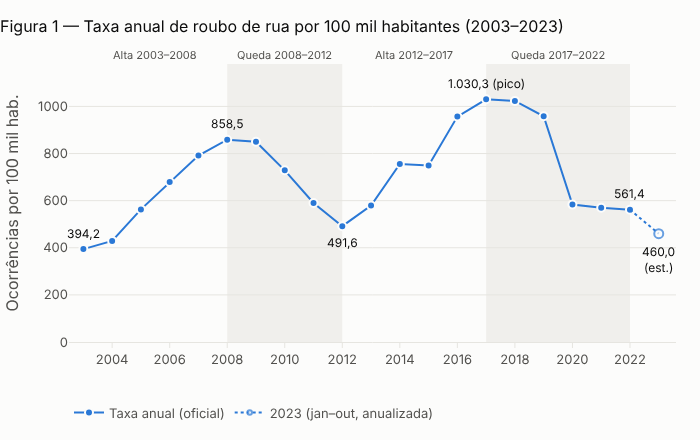

In [12]:
figs["fig1_taxa_anual"].show()

### 4.1 Decomposição STL e detecção de meses atípicos

STL robusta sobre `log(média diária)`; resíduos padronizados por z-score robusto (mediana/MAD).
Limiar |z| > 3,5 (Iglewicz & Hoaglin, 1993).

In [13]:
dec = analysis.decompose(mensal)
dec[dec["outlier"]].round(2)

,media_diaria,tendencia,sazonal,z_robusto,outlier
data,,,,,
2004-02-01,63.93,68.75,1.11,-4.12,True
2012-09-01,74.57,89.12,1.02,-4.51,True
2012-12-01,72.39,90.46,0.95,-3.96,True
2017-01-01,120.65,194.84,1.04,-11.79,True
2017-02-01,75.79,197.32,1.15,-24.92,True
2020-03-01,126.13,146.13,1.07,-5.02,True
2020-04-01,70.97,142.12,1.01,-15.96,True
2020-05-01,65.16,138.82,1.03,-17.84,True
2020-06-01,74.80,135.73,0.97,-12.84,True


INFO | Chromium init'ed with kwargs {}


INFO | Found chromium path: /usr/bin/google-chrome


INFO | Temp directory created: /tmp/tmp64igswxc.


INFO | Opening browser.


INFO | Temp directory created: /tmp/tmpvz3de3oi.


INFO | Temporary directory at: /tmp/tmpvz3de3oi


... (17 outputs left out)

INFO | TemporaryDirectory.cleanup() worked.


INFO | shutil.rmtree worked.


INFO | Cancelling tasks.


INFO | Exiting Kaleido/Choreo.


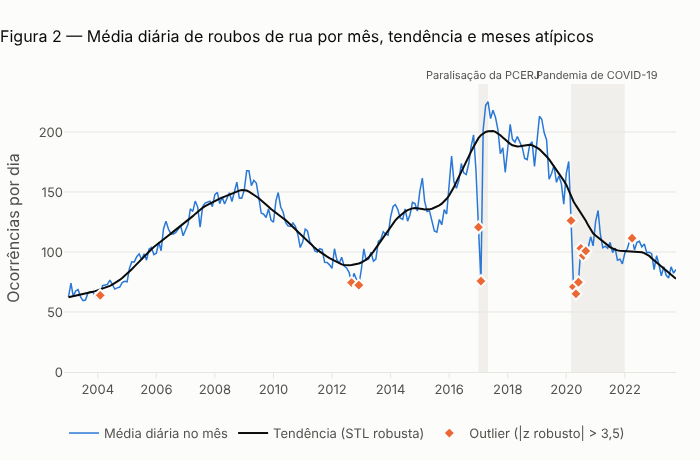

In [14]:
figs["fig2_serie_mensal"].show()

## 5. RQ2 — Sazonalidade

In [15]:
# Contagem bruta vs. média diária: fevereiro muda de posição
tipico = mensal[~(mensal["flag_greve_pc_2017"] | mensal["flag_pandemia"])]
comparacao = pd.DataFrame({
    "contagem_bruta_rel": tipico.groupby("mes")["ocorrencias"].mean() / tipico["ocorrencias"].mean(),
    "indice_sazonal_mediano": analysis.seasonal_index(mensal).groupby("mes")["indice"].median(),
}).round(3)
comparacao.index = etl.MESES
comparacao

,contagem_bruta_rel,indice_sazonal_mediano
Jan,0.984,0.969
Fev,0.985,1.083
Mar,1.029,1.051
Abr,0.975,1.032
Mai,1.06,1.045
Jun,0.989,1.016
Jul,1.004,0.988
Ago,1.002,0.981
Set,0.971,0.989
Out,1.018,1.006


In [16]:
print(f"Kruskal-Wallis H = {met['rq2']['kruskal_H']:.2f}; p = {met['rq2']['kruskal_p']:.2e}; "
      f"epsilon² = {met['rq2']['epsilon2']:.3f}; n = {met['rq2']['n_obs']}")

Kruskal-Wallis H = 64.28; p = 1.47e-09; epsilon² = 0.266; n = 212


INFO | Chromium init'ed with kwargs {}


INFO | Found chromium path: /usr/bin/google-chrome


INFO | Temp directory created: /tmp/tmpz69dyo1l.


INFO | Opening browser.


INFO | Temp directory created: /tmp/tmp1t74mv0p.


INFO | Temporary directory at: /tmp/tmp1t74mv0p


... (15 outputs left out)

INFO | TemporaryDirectory.cleanup() worked.


INFO | shutil.rmtree worked.


INFO | Cancelling tasks.


INFO | Exiting Kaleido/Choreo.


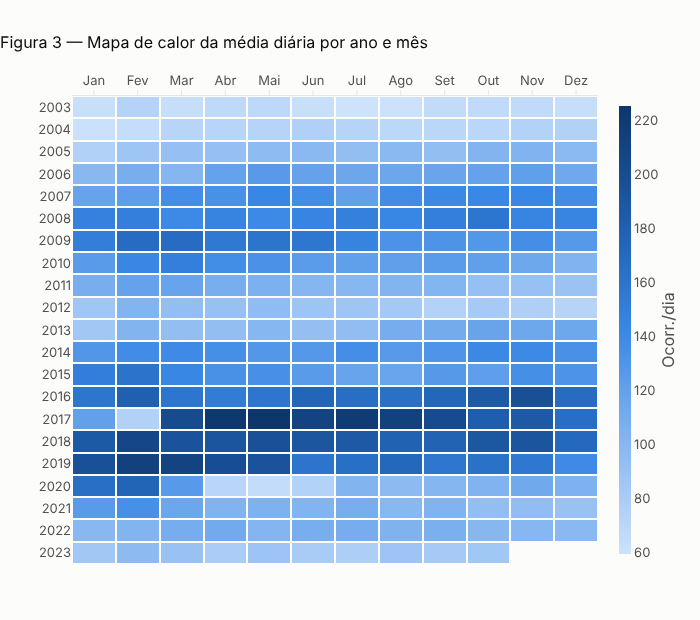

INFO | Chromium init'ed with kwargs {}


INFO | Found chromium path: /usr/bin/google-chrome


INFO | Temp directory created: /tmp/tmpagdhj1hl.


INFO | Opening browser.


INFO | Temp directory created: /tmp/tmponxm3ayo.


INFO | Temporary directory at: /tmp/tmponxm3ayo


... (15 outputs left out)

INFO | TemporaryDirectory.cleanup() worked.


INFO | shutil.rmtree worked.


INFO | Cancelling tasks.


INFO | Exiting Kaleido/Choreo.


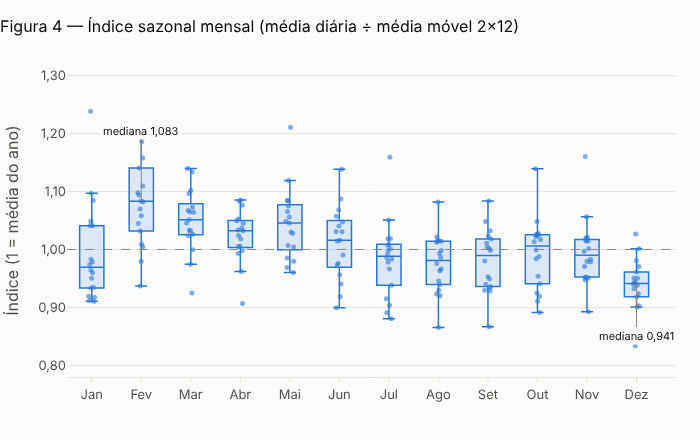

In [17]:
figs["fig3_heatmap"].show()
figs["fig4_sazonalidade"].show()

## 6. RQ3 — Pandemia de COVID-19

In [18]:
p = mensal.pivot(index="mes", columns="ano", values="media_diaria")
vs19 = ((p.div(p[2019], axis=0) - 1) * 100)[[2020, 2021, 2022, 2023]].round(1)
vs19.index = etl.MESES
vs19

ano,2020,2021,2022,2023
Jan,-15.5,-35.9,-49.3,-56.4
Fev,-17.7,-36.8,-51.7,-54.5
Mar,-40.1,-45.4,-48.1,-57.3
Abr,-64.4,-48.1,-44.1,-59.8
Mai,-66.3,-45.8,-47.4,-54.6
Jun,-53.5,-35.8,-32.8,-49.8
Jul,-37.6,-34.6,-34.1,-52.6
Ago,-43.6,-42.2,-39.4,-49.1
Set,-36.2,-34.6,-32.5,-47.9
Out,-36.5,-43.0,-39.1,-47.7


In [19]:
{k: (round(v, 2) if isinstance(v, float) else v) for k, v in met["rq3"].items()}

{'base_2018_2019_media_diaria': 182.82,
 'abr_mai_2020_vs_2019_pct': -65.34,
 'pior_mes_2020': '2020-05',
 'pior_mes_2020_vs_2019_pct': -66.29,
 'jan_fev_2020_vs_2019_pct': -16.64,
 'jun_dez_2019_vs_2018_pct': -13.13,
 'media_diaria_2018_2019': 182.82,
 'media_diaria_2020_mar_dez': 95.96,
 'media_diaria_2021': 106.23,
 'media_diaria_2022': 104.19,
 'media_diaria_2023_jan_out': 85.43,
 'var_2022_vs_base_pct': -43.01,
 'var_2023_vs_base_pct': -53.27,
 'var_vs_2019_por_ano_pct': {2020: -38.702735555541395,
  2021: -39.820645782055465,
  2022: -40.37130360597545,
  2023: -52.98040907196978},
 'mannwhitney_U': 528.0,
 'mannwhitney_p': 0.0}

INFO | Chromium init'ed with kwargs {}


INFO | Found chromium path: /usr/bin/google-chrome


INFO | Temp directory created: /tmp/tmp4ypwsjvl.
INFO | TemporaryDirectory.cleanup() worked.


INFO | shutil.rmtree worked.


INFO | TemporaryDirectory.cleanup() worked.


INFO | shutil.rmtree worked.


... (18 outputs left out)

INFO | TemporaryDirectory.cleanup() worked.


INFO | shutil.rmtree worked.


INFO | Cancelling tasks.


INFO | Exiting Kaleido/Choreo.


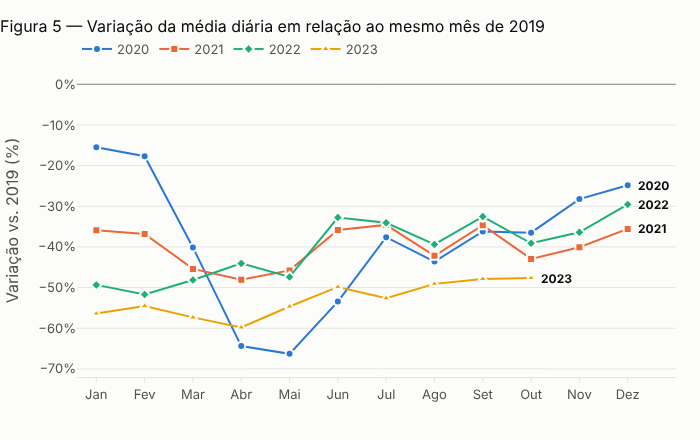

In [20]:
figs["fig5_pandemia"].show()

## 7. Síntese

* **RQ1:** dois ciclos completos (alta 2003–2008, queda 2008–2012, alta 2012–2017, queda 2017–2022); pico em 2017 provavelmente subestimado pela paralisação da Polícia Civil.
* **RQ2:** fevereiro é o mês mais crítico por dia (índice mediano ≈ 1,08) e dezembro o mais calmo (≈ 0,94); diferença significativa (Kruskal-Wallis).
* **RQ3:** queda de ~65% em abr.–mai./2020 vs. 2019, sobreposta a um declínio iniciado em 2019; patamar de 2022–2023 cerca de metade do de 2018–2019.

A discussão completa está no artigo em `docs/index.html`.